# BÀI TẬP 3: PHÂN RÃ CHUỖI THỜI GIAN (TIME-SERIES DECOMPOSITION)
**Môn học:** Quản lý & Khai phá Chuỗi Thời Gian (QLCTG)  
**Nhóm thực hiện:** Nhóm 07  

---
### Mục tiêu bài tập:
1. Phân rã chuỗi theo phương pháp cổ điển: Mô hình Cộng ($Y = T + S + R$) và Mô hình Nhân ($Y = T \times S \times R$).
2. Thực hiện phân rã tiên tiến bằng thuật toán STL (Seasonal and Trend decomposition using Loess).
3. Đánh giá 4 thành phần: Observed, Trend, Seasonal, Residual và so sánh mô hình nào tối ưu hơn.


In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose, STL

plt.rcParams['font.sans-serif'] = ['Segoe UI', 'Arial', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

DATA_PATH = Path("../data/raw/AirPassengers.csv")
FIGURES_DIR = Path("../outputs/figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


### Bước 1: Nạp dữ liệu


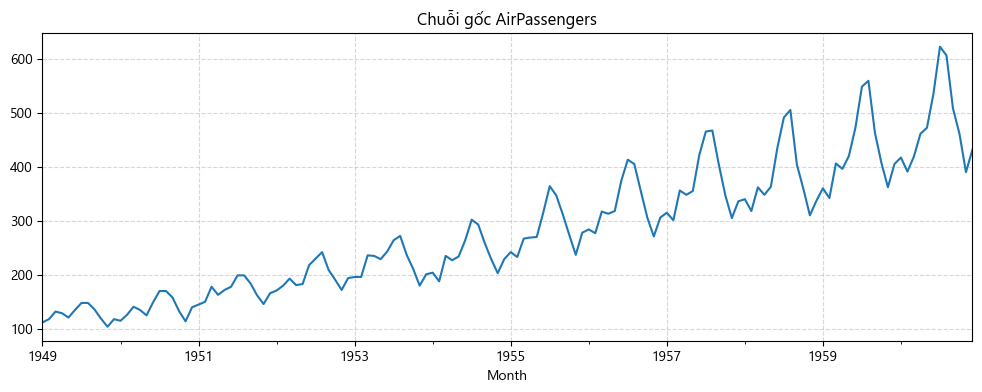

In [2]:
df = pd.read_csv(DATA_PATH)
df['Month'] = pd.to_datetime(df['Month'])
df.set_index('Month', inplace=True)
series = df['Passengers'].astype(float)
series.plot(figsize=(12, 4), title="Chuỗi gốc AirPassengers")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()


### Bước 2: Thực hiện phân rã Additive, Multiplicative và STL


In [3]:
# 1. Classical Additive
decomp_add = seasonal_decompose(series, model="additive", period=12)

# 2. Classical Multiplicative
decomp_mul = seasonal_decompose(series, model="multiplicative", period=12)

# 3. STL Loess
stl = STL(series, period=12, robust=True)
res_stl = stl.fit()

# Tính tăng trưởng Trend
trend_clean = decomp_mul.trend.dropna()
growth_pct = (trend_clean.iloc[-1] / trend_clean.iloc[0] - 1.0) * 100
peak_m = decomp_mul.seasonal.iloc[:12].idxmax().month

print(f"Tốc độ tăng trưởng xu hướng (1949 - 1960): +{growth_pct:.1f}%")
print(f"Tháng có đỉnh mùa vụ cao nhất: Tháng {peak_m}")


Tốc độ tăng trưởng xu hướng (1949 - 1960): +274.7%
Tháng có đỉnh mùa vụ cao nhất: Tháng 7


### Bước 3: Trực quan hóa kết quả phân rã


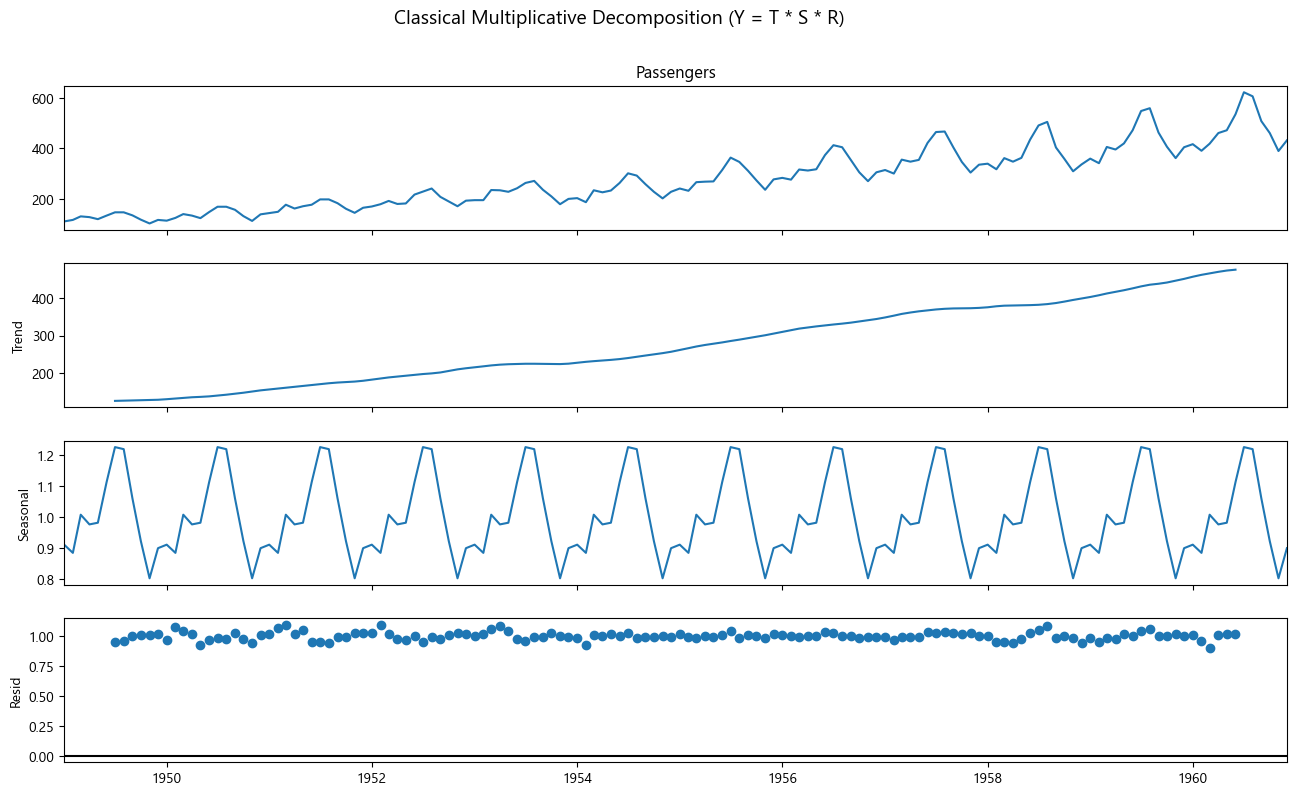

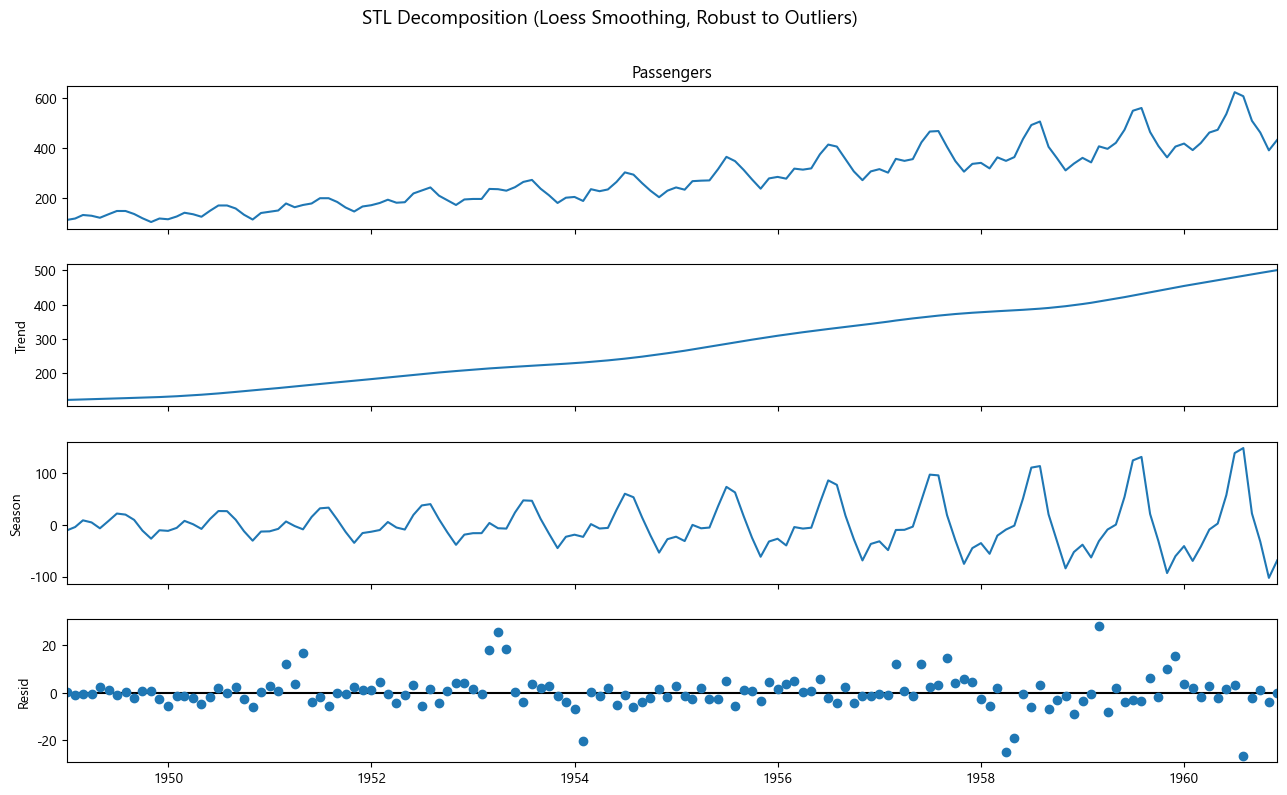

In [4]:
# Đồ thị Multiplicative Decomposition
fig_mul = decomp_mul.plot()
fig_mul.set_size_inches(14, 8)
fig_mul.suptitle("Classical Multiplicative Decomposition (Y = T * S * R)", fontsize=14, y=1.02)
fig_mul.savefig(FIGURES_DIR / "bai3_2_multiplicative_decomposition.png", dpi=300, bbox_inches="tight")
plt.show()

# Đồ thị STL Decomposition
fig_stl = res_stl.plot()
fig_stl.set_size_inches(14, 8)
fig_stl.suptitle("STL Decomposition (Loess Smoothing, Robust to Outliers)", fontsize=14, y=1.02)
fig_stl.savefig(FIGURES_DIR / "bai3_3_stl_decomposition.png", dpi=300, bbox_inches="tight")
plt.show()


### Bước 4: So sánh và Đánh giá học thuật
1. **Xu hướng (Trend):** Tăng trưởng liên tục dốc lên (+274.7%), phản ánh sự bùng nổ của ngành hàng không dân dụng sau Thế chiến 2.
2. **Mùa vụ (Seasonality):** Chu kỳ 12 tháng cực kỳ ổn định, đỉnh rơi vào Tháng 7 và đáy rơi vào Tháng 11.
3. **So sánh Additive vs Multiplicative:** Mô hình Nhân vượt trội hoàn toàn vì biên độ mùa vụ mở rộng tỷ lệ thuận với đường xu hướng (từ chênh ~40 khách năm 1949 lên chênh >150 khách năm 1960). Thành phần Residual của dạng nhân dao động ổn định quanh 1.0 và tiệm cận tính chất của White Noise.
